### Online Retail Data Analysis

#### Objective
Analyze online retail transactions to identify sales trends, top-selling products, country-wise revenue, and high-revenue customers using Python.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df=pd.read_excel(r"C:\Users\yash0\Downloads\online+retail\Online Retail.xlsx")

In [3]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [4]:
df.shape

(541909, 8)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


Basic stats

In [6]:
# Number of customers:
df.CustomerID.unique().shape

(4373,)

In [7]:
# Number of Countries:
df.Country.unique().shape

(38,)

In [8]:
# Start/ End of date:
df.InvoiceDate.min(), df.InvoiceDate.max()

(Timestamp('2010-12-01 08:26:00'), Timestamp('2011-12-09 12:50:00'))

In [9]:
df.isna().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

##### Handling cancelled transection

In [10]:
# Handling cancelled transections:
df.InvoiceNo.str.startswith('C',na= False).sum()

np.int64(9288)

In [11]:
# display those cancelled transection:
df[df.InvoiceNo.str.startswith('C',na= False)].head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom


In [12]:
# Drop those data:
cancelled=df.InvoiceNo.str.startswith('C',na= False)
df_clean= df.drop(df[cancelled].index)

In [13]:
df_clean.InvoiceNo.str.startswith('C',na= False).sum()

np.int64(0)

In [14]:
(df_clean.Quantity<=0).sum()

np.int64(1336)

In [15]:
(df_clean.UnitPrice<=0).sum()

np.int64(2517)

In [16]:
((df_clean.Quantity<=0) & (df_clean.UnitPrice<=0)).sum()

np.int64(1336)

In [17]:
df_clean = df_clean[(df_clean['Quantity'] > 0) & (df_clean['UnitPrice'] > 0)]

In [18]:
((df_clean.Quantity<=0) & (df_clean.UnitPrice<=0)).sum()

np.int64(0)

In [19]:
df_clean['InvoiceDate'].dtype

dtype('<M8[ns]')

In [20]:
df_clean=df_clean.copy()

##### Create Revenue column

In [21]:
df_clean['Revenue']= df_clean['Quantity'] * df_clean['UnitPrice']

In [22]:
df_clean.columns

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country', 'Revenue'],
      dtype='object')

In [23]:
df_clean.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


##### Analyze monthly revenue

In [24]:
monthly_revenue = df_clean.groupby(df_clean['InvoiceDate'].dt.to_period('M'))['Revenue'].sum()

In [25]:
# Which month had the highest revenue?
monthly_revenue.nlargest(5)

InvoiceDate
2011-11    1509496.330
2011-10    1154979.300
2011-09    1058590.172
2010-12     823746.140
2011-05     770536.020
Freq: M, Name: Revenue, dtype: float64

In [26]:
# Which month had the lowest revenue?
monthly_revenue.nsmallest(3)

InvoiceDate
2011-02    523631.890
2011-04    537808.621
2011-12    638792.680
Freq: M, Name: Revenue, dtype: float64

In [27]:
monthly_revenue

InvoiceDate
2010-12     823746.140
2011-01     691364.560
2011-02     523631.890
2011-03     717639.360
2011-04     537808.621
2011-05     770536.020
2011-06     761739.900
2011-07     719221.191
2011-08     759138.380
2011-09    1058590.172
2011-10    1154979.300
2011-11    1509496.330
2011-12     638792.680
Freq: M, Name: Revenue, dtype: float64

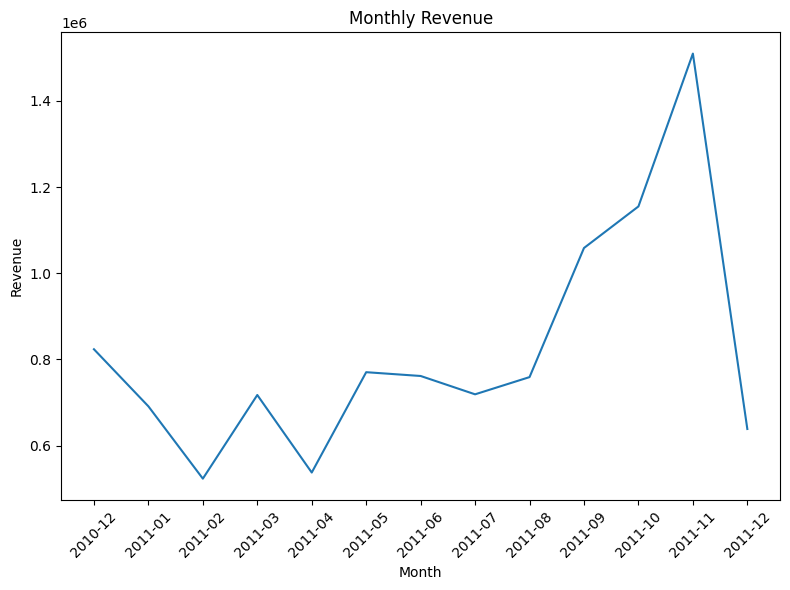

In [28]:
plt.figure(figsize=(8,6))
plt.plot(monthly_revenue.index.astype(str),monthly_revenue.values)
plt.xlabel('Month')
plt.ylabel('Revenue')
plt.title('Monthly Revenue')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

##### Find top-selling products

In [29]:
top_selling= df_clean.groupby('Description')['Quantity'].sum().sort_values(ascending=False)

In [30]:
top_selling.head(10)

Description
PAPER CRAFT , LITTLE BIRDIE           80995
MEDIUM CERAMIC TOP STORAGE JAR        78033
WORLD WAR 2 GLIDERS ASSTD DESIGNS     55047
JUMBO BAG RED RETROSPOT               48474
WHITE HANGING HEART T-LIGHT HOLDER    37891
POPCORN HOLDER                        36761
ASSORTED COLOUR BIRD ORNAMENT         36461
PACK OF 72 RETROSPOT CAKE CASES       36419
RABBIT NIGHT LIGHT                    30788
MINI PAINT SET VINTAGE                26633
Name: Quantity, dtype: int64

##### Find the products that generated the highest revenue

In [31]:
top_revenue_products=(df_clean.groupby('Description')['Revenue']
                      .sum()
                      .sort_values(ascending=False))

top_revenue_products.head(10)

Description
DOTCOM POSTAGE                        206248.77
REGENCY CAKESTAND 3 TIER              174484.74
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HANGING HEART T-LIGHT HOLDER    106292.77
PARTY BUNTING                          99504.33
JUMBO BAG RED RETROSPOT                94340.05
MEDIUM CERAMIC TOP STORAGE JAR         81700.92
Manual                                 78112.82
POSTAGE                                78101.88
RABBIT NIGHT LIGHT                     66964.99
Name: Revenue, dtype: float64

##### Country-wise sales analysis

In [32]:
country_sales=(df_clean.groupby('Country')['Revenue']
              .sum()
              .sort_values(ascending=False))

country_sales.head(10)

Country
United Kingdom    9025222.084
Netherlands        285446.340
EIRE               283453.960
Germany            228867.140
France             209715.110
Australia          138521.310
Spain               61577.110
Switzerland         57089.900
Belgium             41196.340
Sweden              38378.330
Name: Revenue, dtype: float64

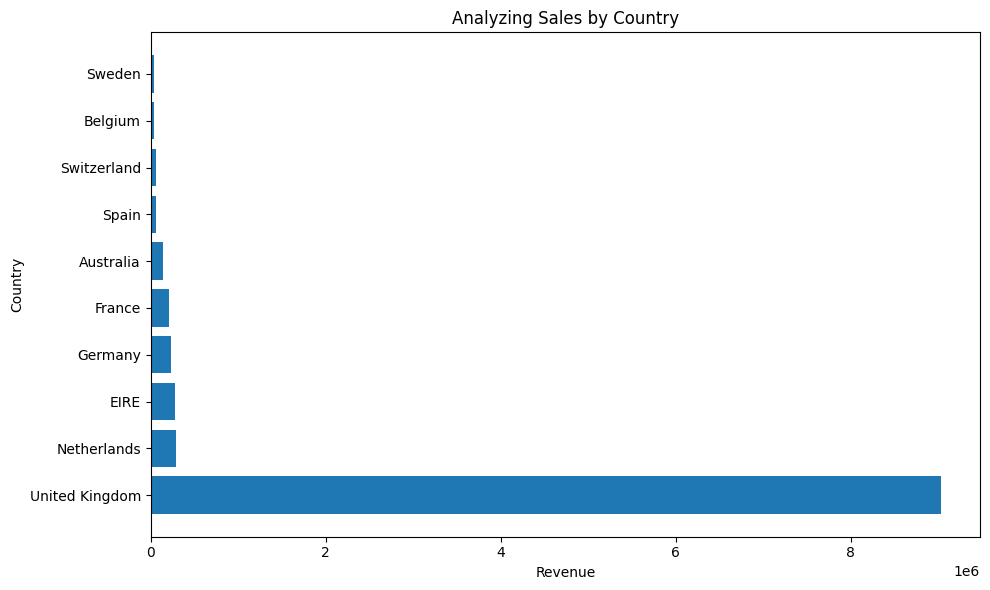

In [33]:
plt.figure(figsize=(10,6))
plt.barh(country_sales.head(10).index,country_sales.head(10).values)
plt.xlabel('Revenue')
plt.ylabel('Country')
plt.title('Analyzing Sales by Country')
plt.tight_layout()
plt.show()

##### Finding Top Customers

In [34]:
# Top customers by revenue:
top_customers= df_clean.groupby('CustomerID')['Revenue'].sum().sort_values(ascending=False)

top_customers.head(10)

CustomerID
14646.0    280206.02
18102.0    259657.30
17450.0    194550.79
16446.0    168472.50
14911.0    143825.06
12415.0    124914.53
14156.0    117379.63
17511.0     91062.38
16029.0     81024.84
12346.0     77183.60
Name: Revenue, dtype: float64

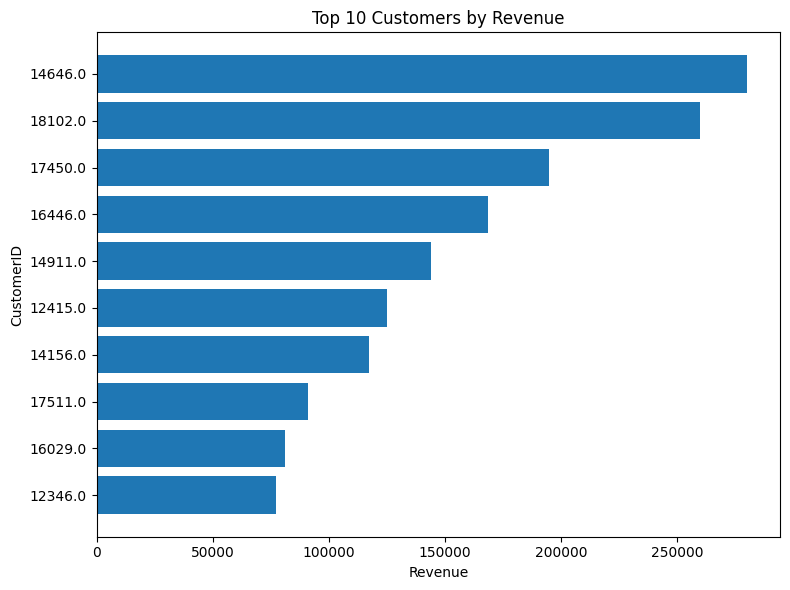

In [35]:
#top10=top_customers.head(10)
plt.figure(figsize=(8,6))
plt.barh(top_customers.head(10).index.astype(str),top_customers.head(10).values)
plt.xlabel('Revenue')
plt.ylabel('CustomerID')
plt.title('Top 10 Customers by Revenue')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

#### Data Cleaning and Preparation
- Missing Value Handling
- Cancelled Invoice Removal
- Invalid Quantity and Price Handling
- Date Validation
- Revenue Calculation

#### Exploratory Data Analysis (EDA)
- Monthly Revenue Analysis
- Country-Wise Revenue
- Top Customers

#### Key Findings and Conclusion

- **Monthly Revenue:** November 2011 recorded the highest monthly revenue at approximately 1.51 million.
- **Country Analysis:** The United Kingdom generated approximately 9.03 million in revenue.
- **Top-Selling Product:** PAPER CRAFT, LITTLE BIRDIE, with 80,995 units sold.
- **Top Customer:** Customer 14646, generating 280,206.02 in revenue.

The analysis revealed important patterns in sales performance, product demand, and customer contributions. Data cleaning and visualization helped turn raw transaction data into useful business insights.